In [1]:
!nvidia-smi


Wed Nov 11 08:47:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import cv2
import os

In [3]:
img=image.load_img('/content/drive/MyDrive/cnn/training/happyface/happy_face_07.png')

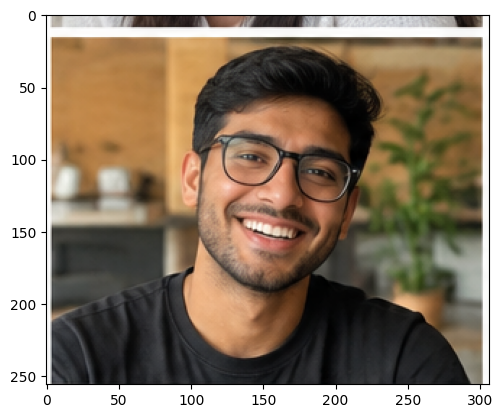

In [4]:
plt.imshow(img)

array([[[252, 252, 252],
        [251, 251, 251],
        [253, 253, 254],
        ...,
        [249, 249, 249],
        [249, 249, 249],
        [249, 249, 249]],

       [[252, 253, 253],
        [252, 252, 252],
        [254, 254, 254],
        ...,
        [249, 249, 250],
        [249, 249, 249],
        [249, 249, 249]],

       [[252, 253, 253],
        [252, 252, 252],
        [254, 255, 255],
        ...,
        [250, 250, 250],
        [250, 250, 250],
        [250, 249, 249]],

       ...,

       [[249, 249, 249],
        [247, 247, 247],
        [253, 252, 252],
        ...,
        [251, 251, 251],
        [251, 251, 251],
        [250, 251, 250]],

       [[250, 250, 250],
        [249, 248, 248],
        [254, 254, 254],
        ...,
        [251, 252, 252],
        [252, 252, 252],
        [252, 252, 252]],

       [[250, 250, 250],
        [249, 249, 249],
        [255, 254, 255],
        ...,
        [252, 252, 252],
        [252, 253, 253],
        [253, 254, 254]]], shape=(256, 307, 3), dtype=uint8)
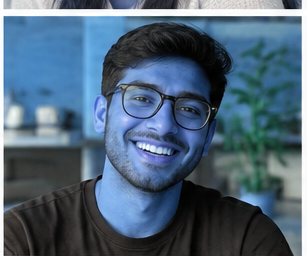

In [5]:
i1=cv2.imread('/content/drive/MyDrive/cnn/training/happyface/happy_face_07.png')
i1
#3 dimension metrices are created fir the image
#the value ranges from from 0-255

In [6]:
i1.shape
#shape of your image height,weight,rgb

(256, 307, 3)

In [7]:
train=ImageDataGenerator(rescale=1/200)
validation=ImageDataGenerator(rescale=1/200)
#to scale all the images i need to divide with 255
#we need to realize the image using 200,200 pixel

In [8]:
train_dataset=train.flow_from_directory('/content/drive/MyDrive/cnn/training',target_size=(200,200),batch_size=32,class_mode='binary')

validation_dataset=validation.flow_from_directory('/content/drive/MyDrive/cnn/validation',target_size=(200,200),batch_size=32,class_mode='binary')

Found 40 images belonging to 2 classes.
Found 0 images belonging to 2 classes.


In [9]:
train_dataset.class_indices

{'happyface': 0, 'sadface': 1}

In [10]:
train_dataset.classes

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [11]:
#now we are applying maxpooling

model=tf.keras.models.Sequential([tf.keras.layers.Conv2D(16,(3,3),activation='relu',
                                                         input_shape=(200,200,3)),
                                  tf.keras.layers.MaxPool2D(2,2),#3 FILTERS ARE APPLIED#
                                  tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
                                  tf.keras.layers.MaxPool2D(2,2),
                                  #
                                   tf.keras.layers.Conv2D(64,(3,3),activation='relu'),
                                  tf.keras.layers.MaxPool2D(2,2),
                                  #
                                   tf.keras.layers.Flatten(),#flatten is linear vector
                                  ##
                                  tf.keras.layers.Dense(512,activation='relu'),#dense fully connected layer
                                  #
                                  tf.keras.layers.Dense(1,activation='sigmoid')])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.compile(loss='binary_crossentropy',optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.001),metrics=['accuracy'])

In [13]:
model_fit=model.fit(train_dataset,epochs=20)

Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 17s 7s/step - accuracy: 0.4500 - loss: 12.1193
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5000 - loss: 2.3144 
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5000 - loss: 0.6873 
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6000 - loss: 0.6790 
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.5000 - loss: 0.6669 
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.4750 - loss: 0.6342 
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6000 - loss: 0.6713 
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - accuracy: 0.8750 - loss: 0.5605
Epoch 9/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.4750 - loss: 0.8773
Epoch 10/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7250 - loss: 0.5725 
Epoch 11/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.8500 - loss: 0.5908
Epoch 12/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.8500 - los

In [14]:
dir_path='/content/drive/MyDrive/cnn/testing'
for i in os.listdir(dir_path):
  print(i)


  #img=image.oad_img(dir_path+'//'+i,target_size=(200,200))
  #plt.imshow(img)
  #plt.show()

happy_face_12.png
happy_face_13.png
happy_face_14.png
happy_face_15.png
happy_face_16.png
happy_face_19.png
happy_face_20.png
sad_face_02.png
sad_face_01.png
sad_face_04.png
sad_face_03.png
sad_face_05.png


In [15]:
dir_path='/content/drive/MyDrive/cnn/testing'
for i in os.listdir(dir_path):
  img=image.load_img(dir_path+'//'+i,target_size=(200,200))
  plt.imshow(img)
  plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [16]:
dir_path='/content/drive/MyDrive/cnn/testing'
for i in os.listdir(dir_path):
  img=image.load_img(dir_path+'//'+i,target_size=(200,200))
  plt.imshow(img)
  plt.show()

  x=image.img_to_array(img)
  x=np.expand_dims(x,axis=0)
  images=np.vstack([x])

  val=model.predict(images)
  if val ==0:
    print("i am happy")

  else:
    print("sad")



Output hidden; open in https://colab.research.google.com to view.

In [17]:
import gradio as gr
from PIL import Image
import numpy as np


def predict_mood(image):
  img=image.resize((200,200))
  x=np.array(img)
  x=np.expand_dims(x,axis=0)
  x=x/200.0
  val=model.predict(x)[0][0]
  if val<0.5:
    return'happy'
  else:
    return 'sad'



In [18]:
iface=gr.Interface(fn=predict_mood,
                   inputs=gr.Image(type="pil",label="upload an image"),
                   outputs=gr.Text(label="Predicted Mood"),
                   title="mood classification (happy/not happy)",
                   description="upload an image ")
iface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fe4545d1036bff1dab.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [19]:
!git clone https://github.com/likithm19/cnn.git

Cloning into 'cnn'...


In [20]:
!cp "/content/CNN(CV).ipynb" "/content/cnn/"

cp: cannot stat '/content/CNN(CV).ipynb': No such file or directory
